In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from datetime import datetime

## data collection

In [3]:
now = datetime.now()
start=datetime(now.year-10,now.month,now.day)
end=now
ticker="GC=F"
df=yf.download(ticker,start,end)
df

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,GC=F,GC=F,GC=F,GC=F,GC=F
Date,,,,,
2016-11-14,1221.199951,1229.500000,1210.400024,1227.800049,216
2016-11-15,1224.000000,1226.000000,1222.500000,1224.300049,20
2016-11-16,1223.400024,1229.300049,1223.000000,1229.300049,66
2016-11-17,1216.500000,1225.000000,1211.000000,1224.599976,1139
2016-11-18,1208.500000,1211.900024,1207.199951,1211.900024,607
...,...,...,...,...,...
2026-11-09,4114.500000,4157.700195,4062.500000,4074.300049,190642
2026-11-10,4030.199951,4156.200195,4020.800049,4149.000000,196165


In [4]:
type(df)

pandas.DataFrame

In [5]:
df.shape

(2516, 5)

In [6]:
df.isnull().sum()

Price   Ticker
Close   GC=F      0
High    GC=F      0
Low     GC=F      0
Open    GC=F      0
Volume  GC=F      0
dtype: int64

In [7]:
df.describe()

Price,Close,High,Low,Open,Volume
Ticker,GC=F,GC=F,GC=F,GC=F,GC=F
count,2516.000000,2516.000000,2516.000000,2516.000000,2516.000000
mean,2119.500278,2136.151550,2102.084142,2119.415263,128901.368839
std,985.838343,1001.439358,969.415508,985.880782,109638.924482
min,1127.800049,1132.800049,1123.900024,1126.900024,0.000000
25%,1341.825012,1347.775024,1335.599976,1341.000000,356.750000
50%,1821.299988,1831.950012,1808.400024,1820.099976,149650.000000
75%,2343.349976,2358.825012,2328.125061,2343.725098,205321.000000
max,5318.399902,5586.200195,5272.899902,5415.700195,570055.000000


In [8]:
df.dtypes

Price   Ticker
Close   GC=F      float64
High    GC=F      float64
Low     GC=F      float64
Open    GC=F      float64
Volume  GC=F        int64
dtype: object

In [9]:
df.head()

Price,Close,High,Low,Open,Volume
Ticker,GC=F,GC=F,GC=F,GC=F,GC=F
Date,,,,,
2016-11-14,1221.199951,1229.500000,1210.400024,1227.800049,216
2016-11-15,1224.000000,1226.000000,1222.500000,1224.300049,20
2016-11-16,1223.400024,1229.300049,1223.000000,1229.300049,66
2016-11-17,1216.500000,1225.000000,1211.000000,1224.599976,1139
2016-11-18,1208.500000,1211.900024,1207.199951,1211.900024,607


In [10]:
df=df.reset_index()
df.head()

Price,Date,Close,High,Low,Open,Volume
Ticker,,GC=F,GC=F,GC=F,GC=F,GC=F
0,2016-11-14,1221.199951,1229.500000,1210.400024,1227.800049,216
1,2016-11-15,1224.000000,1226.000000,1222.500000,1224.300049,20
2,2016-11-16,1223.400024,1229.300049,1223.000000,1229.300049,66
3,2016-11-17,1216.500000,1225.000000,1211.000000,1224.599976,1139
4,2016-11-18,1208.500000,1211.900024,1207.199951,1211.900024,607


Text(0, 0.5, 'closeprice')

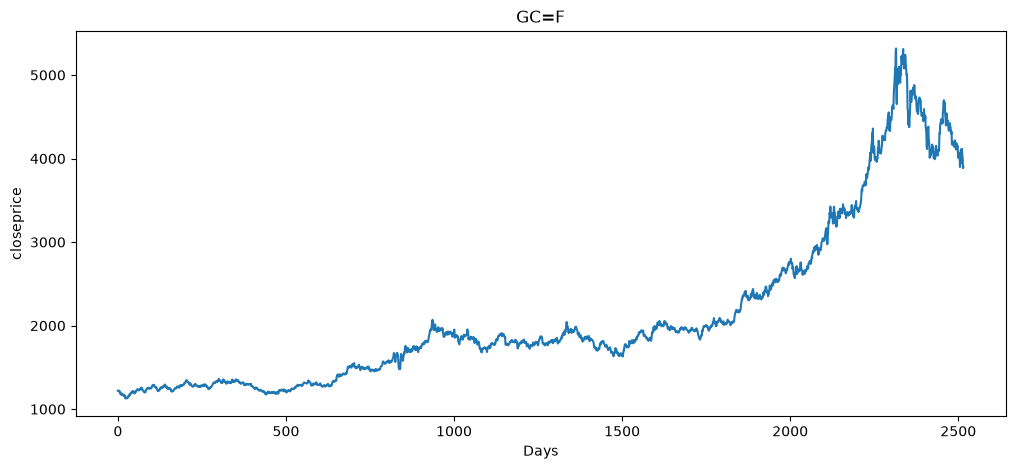

In [11]:
plt.figure(figsize=(12,5))
plt.plot(df.Close)
plt.title(ticker)
plt.xlabel('Days')
plt.ylabel('closeprice')

# Feature Engineering

In [12]:
df1=pd.DataFrame([10,15,20,25,30,35,40,45,50])
df1

,0
0,10
1,15
2,20
3,25
4,30
5,35
6,40
7,45
8,50


In [13]:
df1['MA_5']=df1.rolling(5).mean()
df1

,0,MA_5
0,10,NaN
1,15,NaN
2,20,NaN
3,25,NaN
4,30,20.0
5,35,25.0
6,40,30.0
7,45,35.0
8,50,40.0


In [14]:
df['MA_100']=df.Close.rolling(100).mean()
df.head(1000)

C:\Users\Dell\AppData\Local\Temp\ipykernel_6612\2739391135.py:1: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  df['MA_100']=df.Close.rolling(100).mean()


Price,Date,Close,High,Low,Open,Volume,MA_100
Ticker,,GC=F,GC=F,GC=F,GC=F,GC=F,
0,2016-11-14,1221.199951,1229.500000,1210.400024,1227.800049,216,NaN
1,2016-11-15,1224.000000,1226.000000,1222.500000,1224.300049,20,NaN
2,2016-11-16,1223.400024,1229.300049,1223.000000,1229.300049,66,NaN
3,2016-11-17,1216.500000,1225.000000,1211.000000,1224.599976,1139,NaN
4,2016-11-18,1208.500000,1211.900024,1207.199951,1211.900024,607,NaN
...,...,...,...,...,...,...,...
995,2020-10-29,1868.000000,1885.099976,1859.199951,1877.500000,225159,1891.733002
996,2020-10-30,1879.900024,1890.900024,1863.300049,1867.900024,213173,1893.325002
997,2020-11-02,1892.500000,1897.099976,1873.300049,1877.000000,164943,1894.852002


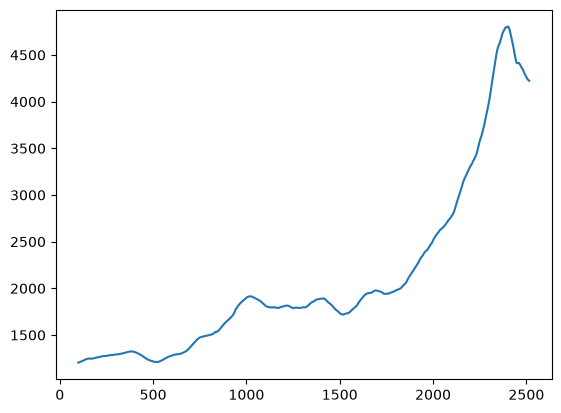

In [15]:
plt.plot(df['MA_100'])

Text(0, 0.5, 'price')

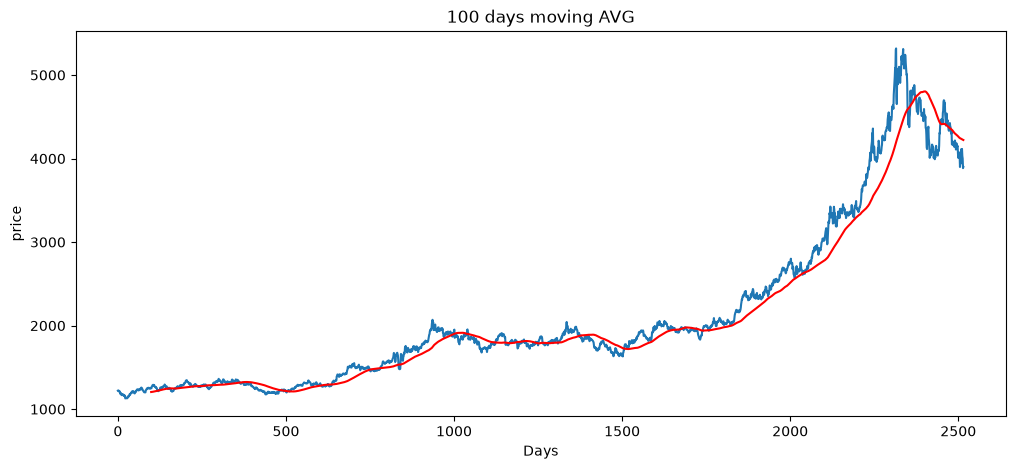

In [16]:
plt.figure(figsize=(12,5))
plt.plot(df.Close)
plt.plot(df['MA_100'],'r')
plt.title("100 days moving AVG")
plt.xlabel('Days')
plt.ylabel('price')

In [17]:
df['MA_200']=df.Close.rolling(200).mean()
df.head(210)

C:\Users\Dell\AppData\Local\Temp\ipykernel_6612\425000304.py:1: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  df['MA_200']=df.Close.rolling(200).mean()


Price,Date,Close,High,Low,Open,Volume,MA_100,MA_200
Ticker,,GC=F,GC=F,GC=F,GC=F,GC=F,,
0,2016-11-14,1221.199951,1229.500000,1210.400024,1227.800049,216,NaN,NaN
1,2016-11-15,1224.000000,1226.000000,1222.500000,1224.300049,20,NaN,NaN
2,2016-11-16,1223.400024,1229.300049,1223.000000,1229.300049,66,NaN,NaN
3,2016-11-17,1216.500000,1225.000000,1211.000000,1224.599976,1139,NaN,NaN
4,2016-11-18,1208.500000,1211.900024,1207.199951,1211.900024,607,NaN,NaN
...,...,...,...,...,...,...,...,...
205,2017-09-08,1346.000000,1355.800049,1345.599976,1351.000000,37,1262.032998,1235.247002
206,2017-09-11,1331.000000,1331.000000,1327.300049,1331.000000,9,1262.528998,1235.847002
207,2017-09-12,1328.000000,1328.000000,1325.199951,1327.000000,15,1262.989998,1236.541502


Text(0, 0.5, 'price')

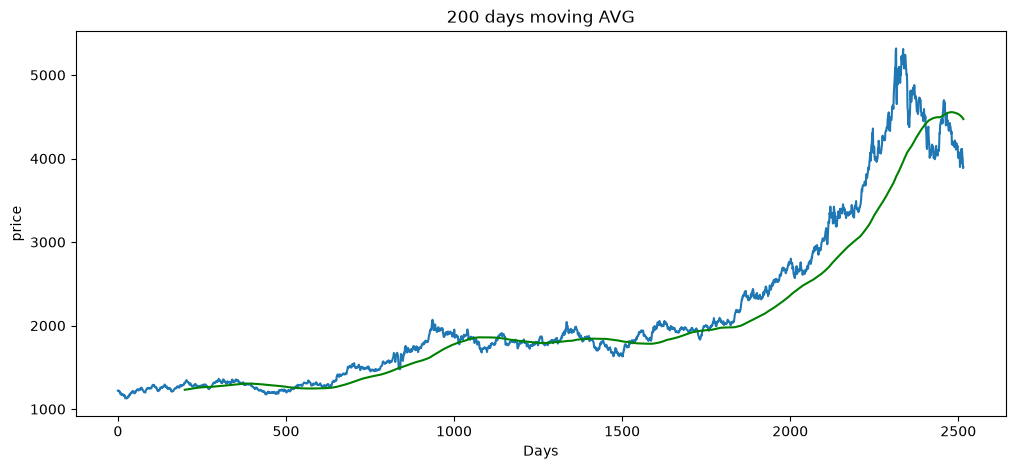

In [18]:
plt.figure(figsize=(12,5))
plt.plot(df.Close)
plt.plot(df['MA_200'],'g')
plt.title("200 days moving AVG")
plt.xlabel('Days')
plt.ylabel('price')

# calculating % changed in each tradig session

In [19]:
df['percentage Changed']=df.Close.pct_change()
df[['Close','percentage Changed']]

C:\Users\Dell\AppData\Local\Temp\ipykernel_6612\1174983883.py:1: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  df['percentage Changed']=df.Close.pct_change()


Price,Close,percentage Changed
Ticker,GC=F,
0,1221.199951,NaN
1,1224.000000,0.002293
2,1223.400024,-0.000490
3,1216.500000,-0.005640
4,1208.500000,-0.006576
...,...,...
2511,4114.500000,0.009718
2512,4030.199951,-0.020489
2513,4000.500000,-0.007369


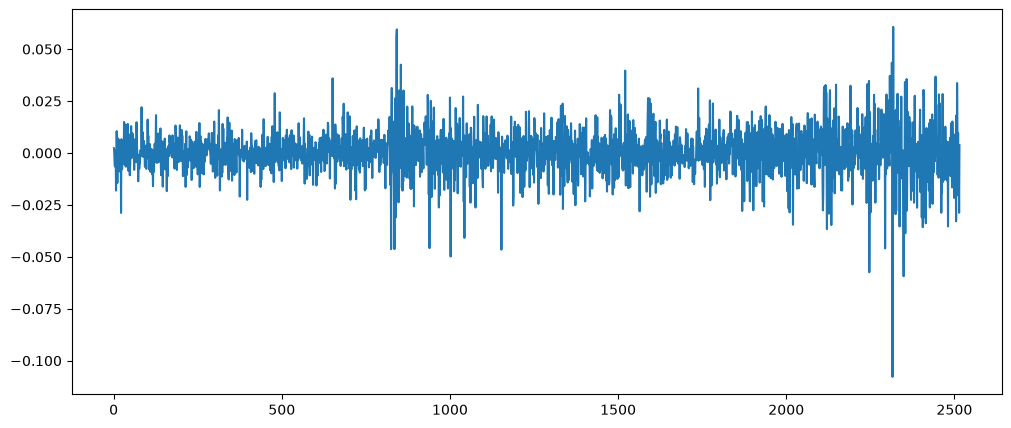

In [20]:
plt.figure(figsize=(12,5))
plt.plot(df['percentage Changed'])

# Data preprocessing

In [21]:
df.shape

(2516, 9)

# splitting data into Training & Teating datasets

In [22]:
data_training=pd.DataFrame(df.Close[0:int(len(df)*0.7)])
data_testing=pd.DataFrame(df.Close[int(len(df)*0.7): int(len(df))])
print(data_training)
print(data_testing)

Ticker         GC=F
0       1221.199951
1       1224.000000
2       1223.400024
3       1216.500000
4       1208.500000
...             ...
1756    1957.800049
1757    1969.800049
1758    1937.699951
1759    1950.199951
1760    1966.500000

[1761 rows x 1 columns]
Ticker         GC=F
1761    1964.300049
1762    1987.300049
1763    1984.699951
1764    1980.300049
1765    2001.599976
...             ...
2511    4114.500000
2512    4030.199951
2513    4000.500000
2514    3885.300049
2515    3900.199951

[755 rows x 1 columns]


In [ ]:
data_training


# Scaling down data between 0 and 1

In [23]:
from sklearn.preprocessing import MinMaxScaler
scaler=MinMaxScaler(feature_range=(0,1))

In [24]:
data_training_array=scaler.fit_transform(data_training)
data_training_array

array([[0.09919277],
       [0.10216649],
       [0.1015293 ],
       ...,
       [0.86013172],
       [0.873407  ],
       [0.89071801]], shape=(1761, 1))

## CREATE DATA SEQUANCE 

In [25]:
x_train=[]
y_train=[]
for i in range(100,data_training_array.shape[0]):
    x_train.append(data_training_array[i-100:i])
    y_train.append(data_training_array[i,0])
x_train,y_train=np.array(x_train),np.array(y_train)    

In [26]:
x_train

array([[[0.09919277],
        [0.10216649],
        [0.1015293 ],
        ...,
        [0.12489379],
        [0.13009773],
        [0.13434582]],

       [[0.10216649],
        [0.1015293 ],
        [0.09420132],
        ...,
        [0.13009773],
        [0.13434582],
        [0.13094727]],

       [[0.1015293 ],
        [0.09420132],
        [0.08570514],
        ...,
        [0.13434582],
        [0.13094727],
        [0.15229389]],

       ...,

       [[0.86777836],
        [0.84526341],
        [0.85152937],
        ...,
        [0.89815217],
        [0.88147847],
        [0.89422274]],

       [[0.84526341],
        [0.85152937],
        [0.85598994],
        ...,
        [0.88147847],
        [0.89422274],
        [0.86013172]],

       [[0.85152937],
        [0.85598994],
        [0.84536972],
        ...,
        [0.89422274],
        [0.86013172],
        [0.873407  ]]], shape=(1661, 100, 1))

In [27]:
y_train


array([0.13094727, 0.15229389, 0.15664828, ..., 0.86013172, 0.873407  ,
       0.89071801], shape=(1661,))

In [28]:
y_train.ndim

1

In [29]:
x_train.ndim

3

In [30]:
import tensorflow as tf
print(tf.__version__)


2.22.0-rc0


In [31]:
import tensorflow as tf
print(tf.__version__)

2.22.0-rc0


# MODEL BUILDING

In [32]:
from keras.models import Sequential
from keras.layers import Dense ,LSTM ,Input

In [33]:
model=Sequential()
model.add(Input(shape=(100,1)))
model.add(LSTM(units=128,activation="tanh",return_sequences=True))
model.add(LSTM(units=64))
model.add(Dense(25))
model.add(Dense(1))

# Model Training

In [34]:
model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

model.fit(
    x_train,
    y_train,
    epochs=50
)

Epoch 1/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 10s 150ms/step - loss: 0.0219
Epoch 2/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 7s 127ms/step - loss: 0.0012
Epoch 3/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 6s 123ms/step - loss: 0.0012
Epoch 4/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 6s 119ms/step - loss: 0.0011
Epoch 5/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 6s 115ms/step - loss: 0.0011
Epoch 6/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 6s 122ms/step - loss: 0.0011
Epoch 7/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 6s 111ms/step - loss: 0.0010
Epoch 8/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 6s 117ms/step - loss: 0.0010
Epoch 9/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 6s 115ms/step - loss: 9.8279e-04
Epoch 10/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 7s 129ms/step - loss: 9.3999e-04
Epoch 11/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 6s 113ms/step - loss: 9.0847e-04
Epoch 12/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 7s 127ms/step - loss: 8.8915e-04
Epoch 13/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 7s 125ms/step - loss: 8.6716e-04
Epoch 14/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 7s 128ms/step - loss: 8.3827e-04
Epoch 15/50
52/52 ━━━━━━━━━━━━━━

In [35]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 100, 128)            │          66,560 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 64)                  │          49,408 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 25)                  │           1,625 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              26 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 352,859 (1.35 MB)

 Trainable params: 117,619 (459.45 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 235,240 (918.91 KB)

# Save 

In [36]:
model.save('stock__prediction__model.keras')

# testing

In [37]:
data_testing

Ticker,GC=F
1761,1964.300049
1762,1987.300049
1763,1984.699951
1764,1980.300049
1765,2001.599976
...,...
2511,4114.500000
2512,4030.199951
2513,4000.500000
2514,3885.300049


In [38]:
data_training

Ticker,GC=F
0,1221.199951
1,1224.000000
2,1223.400024
3,1216.500000
4,1208.500000
...,...
1756,1957.800049
1757,1969.800049
1758,1937.699951
1759,1950.199951


In [39]:
past_100_days=data_training.tail(100)

In [40]:
past_100_days

Ticker,GC=F
1661,1933.800049
1662,1923.800049
1663,1922.199951
1664,1917.900024
1665,1929.400024
...,...
1756,1957.800049
1757,1969.800049
1758,1937.699951
1759,1950.199951


In [41]:
final_df=pd.concat([past_100_days,data_testing],ignore_index=True)
final_df

Ticker,GC=F
0,1933.800049
1,1923.800049
2,1922.199951
3,1917.900024
4,1929.400024
...,...
850,4114.500000
851,4030.199951
852,4000.500000
853,3885.300049


In [42]:
input_data=scaler.fit_transform(final_df)
input_data

array([[2.92548627e-02],
       [2.63867389e-02],
       [2.59278111e-02],
       [2.46945389e-02],
       [2.79928812e-02],
       [2.80215555e-02],
       [2.73331987e-02],
       [2.39775079e-02],
       [2.88819926e-02],
       [2.84517740e-02],
       [3.02013225e-02],
       [3.72569001e-02],
       [3.78592341e-02],
       [3.80313145e-02],
       [3.57368155e-02],
       [4.27350445e-02],
       [4.27350445e-02],
       [3.98955950e-02],
       [3.86622877e-02],
       [3.74003063e-02],
       [3.78305248e-02],
       [3.96661311e-02],
       [3.26679020e-02],
       [3.68840650e-02],
       [3.97808630e-02],
       [4.21614198e-02],
       [4.10715187e-02],
       [3.92932960e-02],
       [4.13870053e-02],
       [3.96374568e-02],
       [3.67406588e-02],
       [3.40732897e-02],
       [3.35857226e-02],
       [3.29260401e-02],
       [3.21803350e-02],
       [2.96563720e-02],
       [2.76773946e-02],
       [2.39201244e-02],
       [2.42929945e-02],
       [2.61572750e-02],


In [43]:
input_data.shape

(855, 1)

In [44]:
x_test=[]
y_test=[]
for i in range(100,input_data.shape[0]):
    x_test.append(input_data[i-100: i])
    y_test.append(input_data[i,0])
    

In [45]:
x_test,y_test=np.array(x_test),np.array(y_test)

In [46]:
x_test

array([[[0.02925486],
        [0.02638674],
        [0.02592781],
        ...,
        [0.0303734 ],
        [0.03395856],
        [0.03863361]],

       [[0.02638674],
        [0.02592781],
        [0.02469454],
        ...,
        [0.03395856],
        [0.03863361],
        [0.03800264]],

       [[0.02592781],
        [0.02469454],
        [0.02799288],
        ...,
        [0.03863361],
        [0.03800264],
        [0.04459932]],

       ...,

       [[0.68000351],
        [0.66471633],
        [0.62439055],
        ...,
        [0.64334881],
        [0.6547066 ],
        [0.63052831]],

       [[0.66471633],
        [0.62439055],
        [0.63551888],
        ...,
        [0.6547066 ],
        [0.63052831],
        [0.62200999]],

       [[0.62439055],
        [0.63551888],
        [0.64948656],
        ...,
        [0.63052831],
        [0.62200999],
        [0.58896922]]], shape=(755, 100, 1))

# Make predictions

In [47]:
y_predicted=model.predict(x_test)

24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 71ms/step


In [48]:
y_predicted

array([[0.03506394],
       [0.03616463],
       [0.03909254],
       [0.04105865],
       [0.04155437],
       [0.04362391],
       [0.0444081 ],
       [0.04466053],
       [0.04571819],
       [0.04758679],
       [0.05183297],
       [0.05582385],
       [0.05732609],
       [0.06307524],
       [0.06266147],
       [0.06040863],
       [0.05987455],
       [0.05988313],
       [0.05679379],
       [0.05210378],
       [0.04882597],
       [0.04756435],
       [0.05211895],
       [0.05534497],
       [0.05741358],
       [0.05950272],
       [0.06024591],
       [0.06071637],
       [0.06280258],
       [0.06457075],
       [0.06808949],
       [0.06968369],
       [0.06902834],
       [0.06834602],
       [0.06478421],
       [0.06279235],
       [0.06198904],
       [0.06012666],
       [0.05869966],
       [0.05736548],
       [0.05563698],
       [0.05777038],
       [0.05771513],
       [0.05465063],
       [0.05354229],
       [0.05407447],
       [0.05404218],
       [0.054

In [49]:
y_predicted=scaler.inverse_transform(y_predicted.reshape(-1,1)).flatten()
y_test=scaler.inverse_transform(y_test.reshape(-1,1)).flatten()

In [50]:
y_predicted


array([1954.054 , 1957.8917, 1968.1001, 1974.9552, 1976.6836, 1983.8993,
       1986.6333, 1987.5134, 1991.2012, 1997.7162, 2012.5209, 2026.4355,
       2031.6732, 2051.7183, 2050.2756, 2042.4207, 2040.5586, 2040.5885,
       2029.8174, 2013.465 , 2002.0367, 1997.6378, 2013.5181, 2024.7657,
       2031.9783, 2039.2622, 2041.8535, 2043.4938, 2050.7673, 2056.9324,
       2069.201 , 2074.759 , 2072.474 , 2070.0952, 2057.6768, 2050.732 ,
       2047.9309, 2041.4376, 2036.4623, 2031.8105, 2025.784 , 2033.2223,
       2033.0295, 2022.3448, 2018.4805, 2020.336 , 2020.2235, 2020.9141,
       2017.9574, 2015.8776, 2014.6182, 2016.9541, 2021.4631, 2030.8588,
       2046.0402, 2050.3462, 2046.4679, 2045.3188, 2045.5197, 2044.7937,
       2040.9935, 2036.0413, 2023.5602, 2013.1616, 2011.036 , 2014.9406,
       2024.2986, 2029.1606, 2029.5059, 2035.1593, 2035.9528, 2037.1355,
       2037.4844, 2041.9615, 2060.8135, 2087.228 , 2110.9673, 2130.8228,
       2144.5122, 2159.2349, 2169.715 , 2166.7146, 

In [51]:
y_test

array([1964.30004883, 1987.30004883, 1984.69995117, 1980.30004883,
       2001.59997559, 1992.80004883, 1993.30004883, 2003.        ,
       2012.40002441, 2040.        , 2047.09997559, 2038.09997559,
       2089.69995117, 2042.19995117, 2036.30004883, 2047.90002441,
       2046.40002441, 2014.5       , 1993.69995117, 1993.19995117,
       1997.30004883, 2044.90002441, 2035.69995117, 2040.5       ,
       2052.10009766, 2047.69995117, 2051.30004883, 2069.10009766,
       2069.80004883, 2093.10009766, 2083.5       , 2071.80004883,
       2073.39990234, 2042.80004883, 2050.        , 2049.80004883,
       2033.5       , 2033.        , 2027.80004883, 2019.19995117,
       2051.60009766, 2030.19995117, 2006.5       , 2021.59997559,
       2029.30004883, 2022.19995117, 2025.80004883, 2016.        ,
       2017.80004883, 2017.30004883, 2025.40002441, 2031.5       ,
       2048.39990234, 2071.10009766, 2053.69995117, 2042.90002441,
       2051.39990234, 2051.69995117, 2047.90002441, 2038.69995

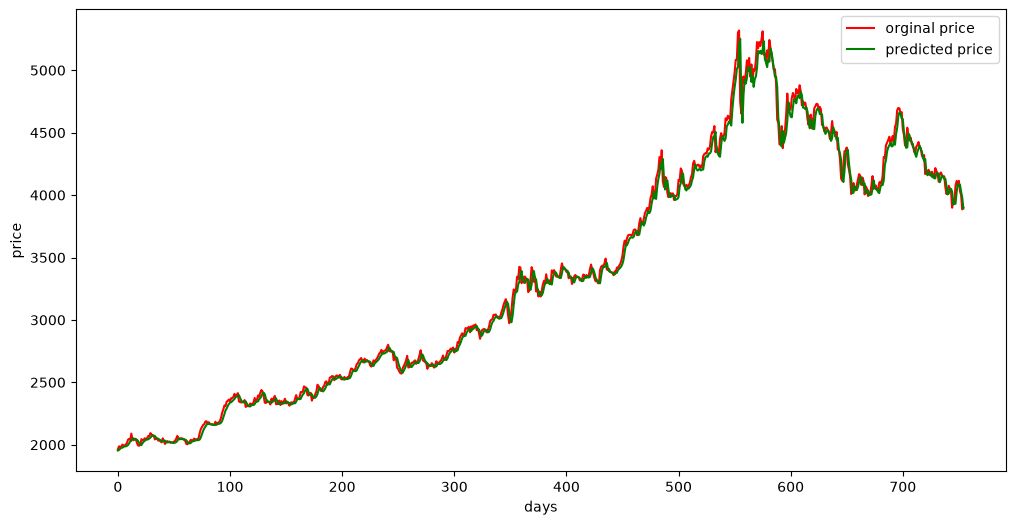

In [52]:
plt.figure(figsize=(12,6))
plt.plot(y_test,'red',label="orginal price")
plt.plot(y_predicted,'g',label="predicted price")
plt.xlabel('days')
plt.ylabel('price')
plt.legend()

# model evaluvation

In [53]:
#Mean squared error(mse)
from sklearn.metrics import mean_squared_error,r2_score

In [54]:
mse=mean_squared_error(y_test,y_predicted)
print(mse)
rmse=np.sqrt(mse)
print(rmse)
r2=r2_score(y_test,y_predicted)
print(r2)

3749.5372420065655
61.233465049812146
0.995789526936976


In [55]:
rmse=np.sqrt(mse)
print(rmse)

61.233465049812146


In [56]:
r2=r2_score(y_test,y_predicted)
print(r2)

0.995789526936976
